# Task 2: Exploratory Data Analysis

**Dataset:** BigMart Sales (cleaned in Task 1)
**Objective:** Summarise the main characteristics of the data using statistics and visualizations, and find patterns, relationships and insights that explain item sales.

## Summary of Findings
- Outlet type is the strongest driver of sales: Type3 supermarkets average 3,694 per item against 340 for grocery stores.
- Item price (MRP) is the strongest numeric predictor (correlation 0.57).
- Product category and fat content have little effect on sales.
- Sales are right-skewed: a few high sellers, all in supermarkets, pull the average up.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")       # light grid background for all charts
pd.set_option("display.max_columns", 50)
print("All libraries imported successfully!")

All libraries imported successfully!


## 1. Load and Inspect the Cleaned Dataset

In [2]:
# Load the readable cleaned file from Task 1
df = pd.read_csv("../data/cleaned/bigmart_cleaned.csv")

print("Rows, columns:", df.shape)
display(df.head())
df.info()

Rows, columns: (8523, 13)


,item_identifier,item_weight,item_fat_content,item_visibility,item_type,item_mrp,outlet_identifier,outlet_establishment_year,outlet_size,outlet_location_type,outlet_type,item_outlet_sales,sales_outlier_flag
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,False
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,False
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,False
3,FDX07,19.20,Regular,0.022911,Fruits and Vegetables,182.0950,OUT010,1998,Small,Tier 3,Grocery Store,732.3800,False
4,NCD19,8.93,Non-Edible,0.016164,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052,False


<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   item_identifier            8523 non-null   str    
 1   item_weight                8523 non-null   float64
 2   item_fat_content           8523 non-null   str    
 3   item_visibility            8523 non-null   float64
 4   item_type                  8523 non-null   str    
 5   item_mrp                   8523 non-null   float64
 6   outlet_identifier          8523 non-null   str    
 7   outlet_establishment_year  8523 non-null   int64  
 8   outlet_size                8523 non-null   str    
 9   outlet_location_type       8523 non-null   str    
 10  outlet_type                8523 non-null   str    
 11  item_outlet_sales          8523 non-null   float64
 12  sales_outlier_flag         8523 non-null   bool   
dtypes: bool(1), float64(4), int64(1), str(7)
memory usage: 807.

## 2. Descriptive Statistics

In [3]:
num_cols = ["item_weight", "item_visibility", "item_mrp",
            "outlet_establishment_year", "item_outlet_sales"]

# count, mean, std, min, quartiles (25%, 50% = median, 75%) and max
display(df[num_cols].describe().round(2))

# Skewness: 0 = symmetric, positive = long tail to the right, negative = long tail to the left
print("Skewness:")
print(df[num_cols].skew().round(2))

,item_weight,item_visibility,item_mrp,outlet_establishment_year,item_outlet_sales
count,8523.00,8523.00,8523.00,8523.00,8523.00
mean,12.88,0.07,140.99,1997.83,2181.29
std,4.65,0.05,62.28,8.37,1706.50
min,4.56,0.00,31.29,1985.00,33.29
25%,8.78,0.03,93.83,1987.00,834.25
50%,12.65,0.06,143.01,1999.00,1794.33
75%,16.85,0.10,185.64,2004.00,3101.30
max,21.35,0.20,266.89,2009.00,13086.96


Skewness:
item_weight                  0.07
item_visibility              0.86
item_mrp                     0.13
outlet_establishment_year   -0.40
item_outlet_sales            1.18
dtype: float64


In [4]:
cat_cols = ["item_fat_content", "item_type", "outlet_size",
            "outlet_location_type", "outlet_type"]

# How many distinct values, the most common one, and how often it appears
display(df[cat_cols].describe())

# The share of rows in each category (useful for the report)
for c in ["item_fat_content", "outlet_size", "outlet_location_type", "outlet_type"]:
    print(f"\n{c}")
    print((df[c].value_counts(normalize=True) * 100).round(1))

,item_fat_content,item_type,outlet_size,outlet_location_type,outlet_type
count,8523,8523,8523,8523,8523
unique,3,16,3,3,4
top,Low Fat,Fruits and Vegetables,Small,Tier 3,Supermarket Type1
freq,3918,1232,4798,3350,5577



item_fat_content
item_fat_content
Low Fat       46.0
Regular       35.3
Non-Edible    18.8
Name: proportion, dtype: float64

outlet_size
outlet_size
Small     56.3
Medium    32.8
High      10.9
Name: proportion, dtype: float64

outlet_location_type
outlet_location_type
Tier 3    39.3
Tier 2    32.7
Tier 1    28.0
Name: proportion, dtype: float64

outlet_type
outlet_type
Supermarket Type1    65.4
Grocery Store        12.7
Supermarket Type3    11.0
Supermarket Type2    10.9
Name: proportion, dtype: float64


**Interpretation.** `item_outlet_sales` has a mean of 2,181 but a median of 1,794, and a skewness of 1.18, so a few very high sellers pull the average up. The maximum (13,087) is about six times the mean. `item_visibility` is also right-skewed (0.86), while `item_weight` (0.07) and `item_mrp` (0.13) are close to symmetric. Among categories, 65.4% of rows come from Supermarket Type1, 56.3% from Small outlets (this includes the three outlets whose size was filled during cleaning) and 46.0% are Low Fat items.

## 3. Distributions (Histograms and KDE Plots)

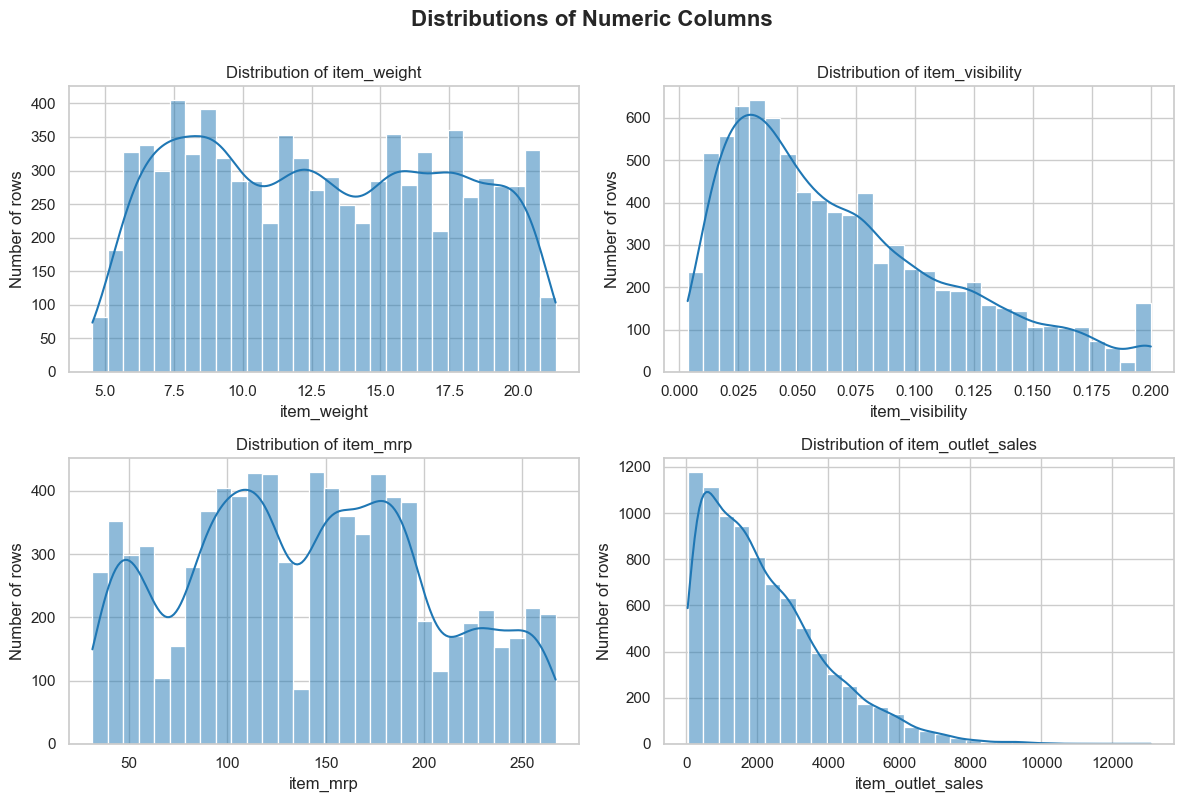

In [5]:
dist_cols = ["item_weight", "item_visibility", "item_mrp", "item_outlet_sales"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))        # a page with 2 x 2 chart boxes

for ax, col in zip(axes.flatten(), dist_cols):
    # histplot draws the bars (a histogram); kde=True adds the smooth curve (KDE) on top
    sns.histplot(df[col], kde=True, bins=30, color="#1f77b4", ax=ax)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of rows")

plt.suptitle("Distributions of Numeric Columns", fontsize=16, fontweight="bold", y=1.0)
plt.tight_layout()
plt.savefig("../outputs/charts/eda_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** `item_outlet_sales` is right-skewed: three quarters of the rows sell less than about 3,100, with a long tail up to 13,087. `item_visibility` is also right-skewed and peaks near 0.03. The small spike at 0.20 comes from capping 144 extreme values in Task 1. `item_mrp` has several peaks, which suggests distinct price bands, and `item_weight` is spread almost evenly between about 5 and 21.

## 4. Correlation Analysis

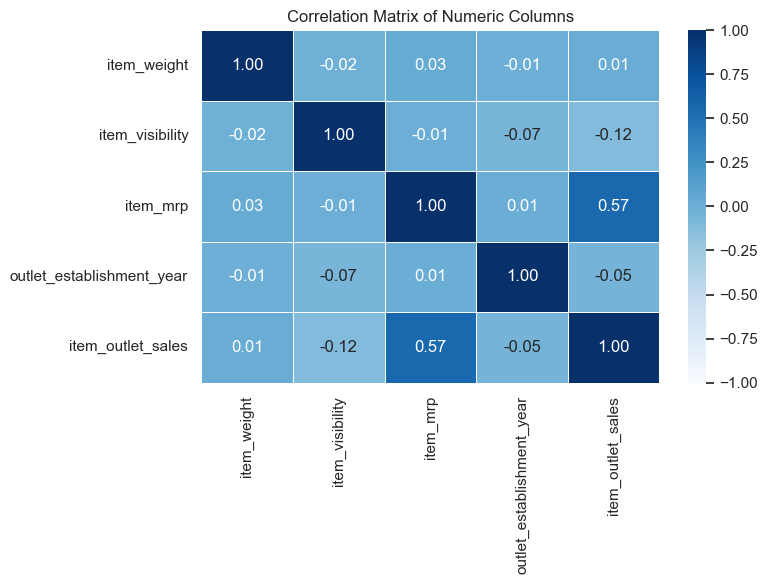

item_mrp                     0.57
item_weight                  0.01
outlet_establishment_year   -0.05
item_visibility             -0.12
Name: item_outlet_sales, dtype: float64


In [6]:
# Correlation: how strongly two numeric columns move together (-1 to +1)
corr = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numeric Columns")
plt.tight_layout()
plt.savefig("../outputs/charts/eda_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Which columns are most related to sales?
print(corr["item_outlet_sales"].drop("item_outlet_sales").sort_values(ascending=False).round(2))

**Interpretation.** `item_outlet_sales` has its strongest relationship with `item_mrp` (0.57): items with a higher list price tend to have higher sales values. `item_visibility` has a weak negative association (-0.12), and `item_weight` (0.01) and `outlet_establishment_year` (-0.05) have almost no straight-line association with sales. The input columns are barely correlated with each other (between -0.07 and 0.03), so none of them repeats the information in another. Correlation only measures straight-line relationships between numbers, so the effect of categories such as outlet type is checked in the next steps.

## 5. Box Plots by Category

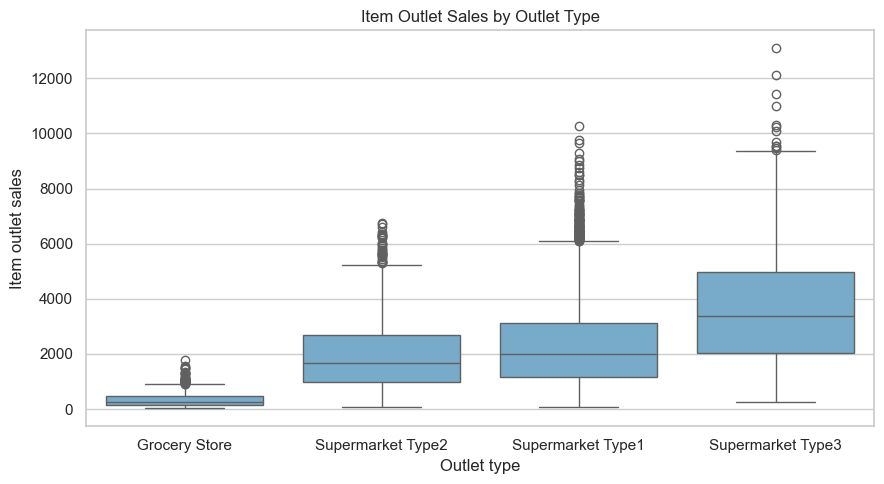

,count,median,mean
outlet_type,,,
Grocery Store,1083,257.0,340.0
Supermarket Type1,5577,1991.0,2316.0
Supermarket Type2,928,1655.0,1995.0
Supermarket Type3,935,3365.0,3694.0


In [7]:
# Sales by outlet type
# Order the boxes from the lowest median sales to the highest
order = list(df.groupby("outlet_type")["item_outlet_sales"].median().sort_values().index)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="outlet_type", y="item_outlet_sales", order=order, color="#6baed6")
plt.title("Item Outlet Sales by Outlet Type")
plt.xlabel("Outlet type")
plt.ylabel("Item outlet sales")
plt.tight_layout()
plt.savefig("../outputs/charts/eda_boxplot_outlet_type.png", dpi=300, bbox_inches="tight")
plt.show()

# The median and count behind each box
df.groupby("outlet_type")["item_outlet_sales"].agg(["count", "median", "mean"]).round(0)

**Interpretation.** Sales differ sharply by outlet type. Supermarket Type3 has the highest median (3,365) and mean (3,694), while grocery stores have a median of only 257. Type3's average is about 60% above Type1 (2,316) and almost 11 times the grocery store average (340). Type1 and Type3 also show the most high-value outliers, so the largest sales come from the bigger supermarkets.

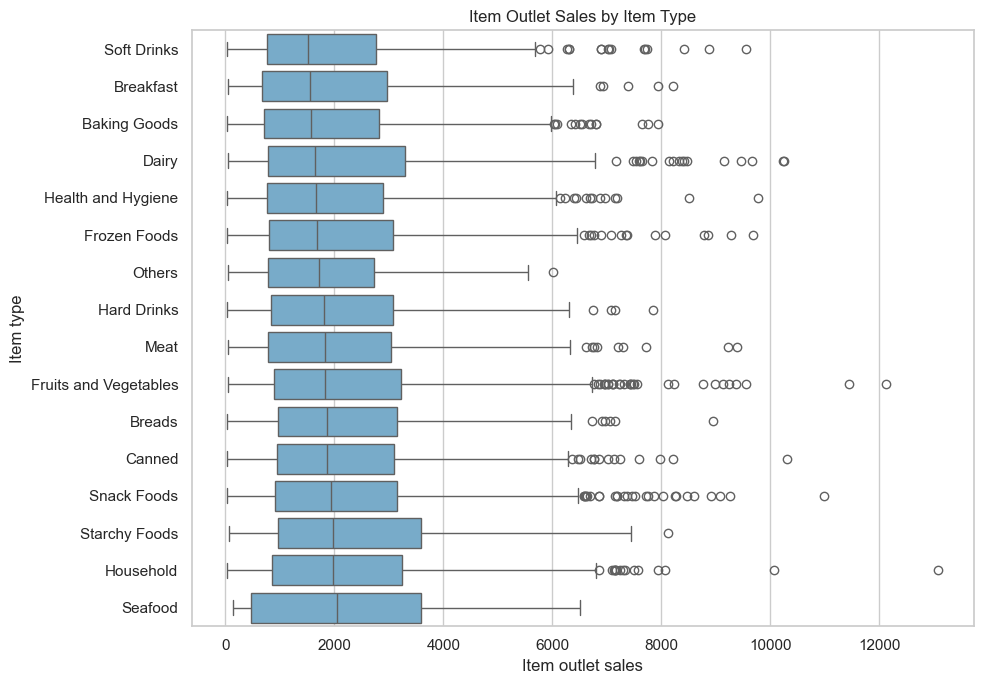

In [8]:
# Sales by item type

order = list(df.groupby("item_type")["item_outlet_sales"].median().sort_values().index)

plt.figure(figsize=(10, 7))
sns.boxplot(data=df, y="item_type", x="item_outlet_sales", order=order, color="#6baed6")
plt.title("Item Outlet Sales by Item Type")
plt.xlabel("Item outlet sales")
plt.ylabel("Item type")
plt.tight_layout()
plt.savefig("../outputs/charts/eda_boxplot_item_type.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** The medians of the 16 item types are close together, roughly between 1,500 and 2,100, and the boxes overlap heavily. Every item type has high outliers. So the type of product tells us much less about sales than the type of outlet does.

## 6. Trend by Outlet Establishment Year
The dataset has no order dates, so the outlet establishment year is used as the time axis. Each point compares outlets that opened in that year, so this shows how outlets differ by age, not how sales changed over time.

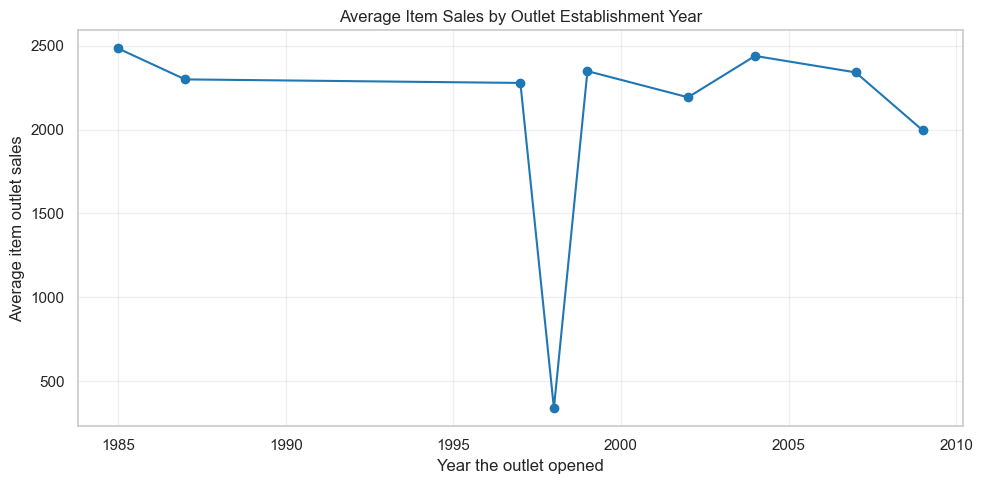

count    mean
outlet_establishment_year outlet_identifier outlet_type                     
1985                      OUT019            Grocery Store        528   340.0
                          OUT027            Supermarket Type3    935  3694.0
1987                      OUT013            Supermarket Type1    932  2299.0
1997                      OUT046            Supermarket Type1    930  2278.0
1998                      OUT010            Grocery Store        555   339.0
1999                      OUT049            Supermarket Type1    930  2348.0
2002                      OUT045            Supermarket Type1    929  2192.0
2004                      OUT035            Supermarket Type1    930  2439.0
2007                      OUT017            Supermarket Type1    926  2341.0
2009                      OUT018            Supermarket Type2    928  1995.0

In [9]:
yearly = df.groupby("outlet_establishment_year")["item_outlet_sales"].mean()

plt.figure(figsize=(10, 5))
plt.plot(yearly.index, yearly.values, marker="o", color="#1f77b4")
plt.title("Average Item Sales by Outlet Establishment Year")
plt.xlabel("Year the outlet opened")
plt.ylabel("Average item outlet sales")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../outputs/charts/eda_sales_by_year.png", dpi=300, bbox_inches="tight")
plt.show()

# Which outlets sit behind each year? (needed to read the chart correctly)
df.groupby(["outlet_establishment_year", "outlet_identifier", "outlet_type"])["item_outlet_sales"].agg(["count", "mean"]).round(0)

**Interpretation.** Average sales are fairly flat across establishment years (about 2,000 to 2,500), except for a sharp dip in 1998. The table shows that this year belongs to a single outlet, OUT010, which is a grocery store (average sales 339). The 1985 average is lifted by OUT027, a Type3 supermarket (3,694), and pulled down by the grocery store OUT019. So the pattern comes from outlet type and not from the outlet's age.

## 7. Group-by Analysis

In [10]:
for col in ["outlet_type", "outlet_location_type", "outlet_size", "item_fat_content"]:
    print(f"\nAverage sales by {col}")
    print(df.groupby(col)["item_outlet_sales"].agg(["count", "mean", "median"]).round(0).sort_values("mean", ascending=False))


Average sales by outlet_type
                   count    mean  median
outlet_type                             
Supermarket Type3    935  3694.0  3365.0
Supermarket Type1   5577  2316.0  1991.0
Supermarket Type2    928  1995.0  1655.0
Grocery Store       1083   340.0   257.0

Average sales by outlet_location_type
                      count    mean  median
outlet_location_type                       
Tier 2                 2785  2324.0  2004.0
Tier 3                 3350  2280.0  1812.0
Tier 1                 2388  1877.0  1487.0

Average sales by outlet_size
             count    mean  median
outlet_size                       
Medium        2793  2682.0  2251.0
High           932  2299.0  2051.0
Small         4798  1867.0  1484.0

Average sales by item_fat_content
                  count    mean  median
item_fat_content                       
Regular            3006  2225.0  1845.0
Low Fat            3918  2164.0  1733.0
Non-Edible         1599  2143.0  1875.0


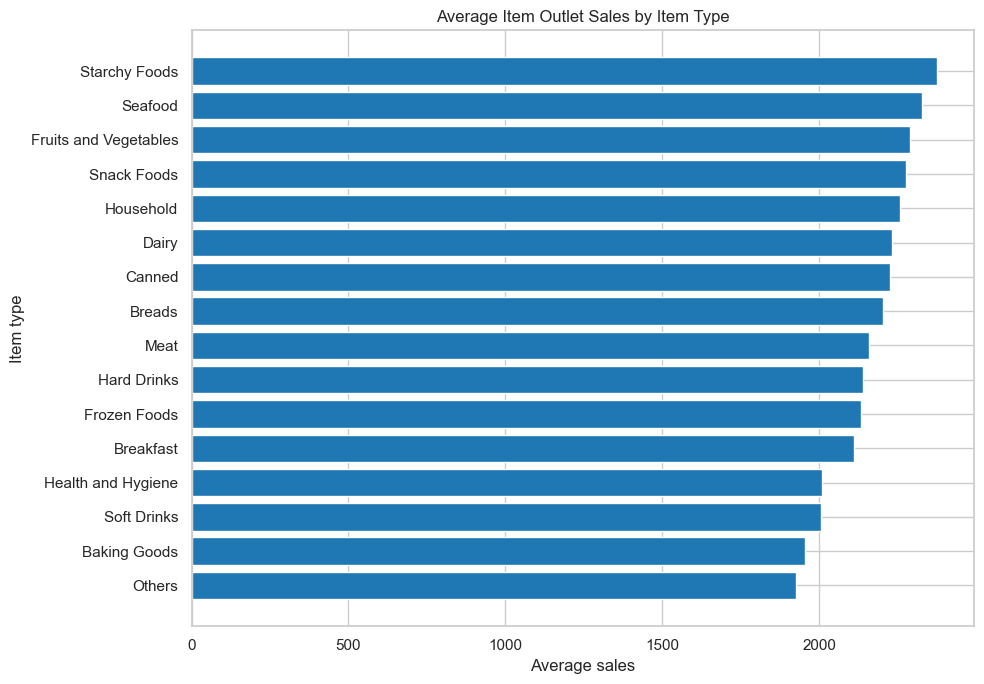

In [11]:
# average sales by item type, as a bar chart
by_type = df.groupby("item_type")["item_outlet_sales"].mean().sort_values()

plt.figure(figsize=(10, 7))
plt.barh(by_type.index, by_type.values, color="#1f77b4")
plt.title("Average Item Outlet Sales by Item Type")
plt.xlabel("Average sales")
plt.ylabel("Item type")
plt.tight_layout()
plt.savefig("../outputs/charts/eda_avg_sales_item_type.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
share = (df.groupby("outlet_type")["item_outlet_sales"].sum() / df["item_outlet_sales"].sum() * 100).round(1)
print(share.sort_values(ascending=False))

outlet_type
Supermarket Type1    69.5
Supermarket Type3    18.6
Supermarket Type2    10.0
Grocery Store         2.0
Name: item_outlet_sales, dtype: float64


**Interpretation.** Supermarket Type1 generates 69.5% of total sales because it has 5,577 rows (65.4% of the data), while Type3 generates 18.6% from only 935 rows. Grocery stores make up 12.7% of rows but only 2.0% of sales. Medium outlets (2,682) average about 44% more than Small ones (1,867), and Tier 2 and Tier 3 locations (2,324 and 2,280) average more than Tier 1 (1,877). These size and tier differences partly reflect which outlet types sit in each group. Fat content makes little difference (Regular 2,225, Low Fat 2,164, Non-Edible 2,143), and item types range only from about 1,900 (Others) to 2,400 (Starchy Foods).

## 8. Relationships Between Variables (Scatter Plots)

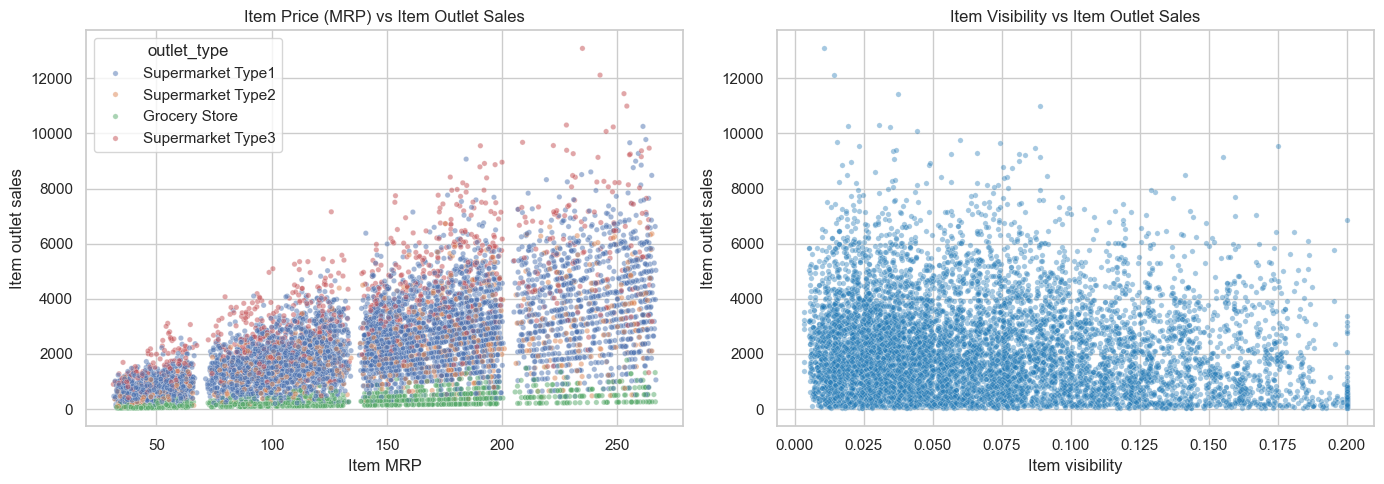

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Price vs sales, coloured by outlet type
sns.scatterplot(data=df, x="item_mrp", y="item_outlet_sales", hue="outlet_type",
                alpha=0.5, s=15, ax=axes[0])
axes[0].set_title("Item Price (MRP) vs Item Outlet Sales")
axes[0].set_xlabel("Item MRP")
axes[0].set_ylabel("Item outlet sales")

# Visibility vs sales
sns.scatterplot(data=df, x="item_visibility", y="item_outlet_sales",
                alpha=0.4, s=15, color="#1f77b4", ax=axes[1])
axes[1].set_title("Item Visibility vs Item Outlet Sales")
axes[1].set_xlabel("Item visibility")
axes[1].set_ylabel("Item outlet sales")

plt.tight_layout()
plt.savefig("../outputs/charts/eda_scatter_plots.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation.** Sales rise with item price (MRP), in line with the 0.57 correlation. The points form vertical bands, which suggests that items fall into distinct price groups. Grocery stores (green) sit at the bottom at every price level, and Type3 supermarkets (red) reach the highest sales. Visibility shows no clear pattern: items with high visibility do not sell more, and the slight downward trend is explained by outlet type (see the note below).

In [14]:
df.groupby("outlet_type")["item_visibility"].mean().round(3)

outlet_type
Grocery Store        0.102
Supermarket Type1    0.065
Supermarket Type2    0.066
Supermarket Type3    0.063
Name: item_visibility, dtype: float64

**Note on visibility.** Grocery stores have the highest average item visibility (0.102, against about 0.063 to 0.066 in the supermarkets) but by far the lowest sales. The weak negative correlation between visibility and sales (-0.12) therefore mostly reflects outlet type and does not show that higher visibility reduces sales.

## 9. Key Insights

1. **Outlet type is the strongest driver of sales.** Type3 supermarkets average 3,694 per item against 2,316 for Type1, 1,995 for Type2 and 340 for grocery stores. Grocery stores hold 12.7% of rows but only 2.0% of total sales.
2. **Price is the strongest numeric predictor.** `item_mrp` has a correlation of 0.57 with sales, and the other numeric columns are all below 0.12 in absolute value.
3. **Product category matters little.** Average sales across the 16 item types range only from about 1,900 to 2,400, and fat content changes the average by under 4%.
4. **Sales are concentrated in a few high sellers.** Sales are right-skewed (skewness 1.18), and the 186 flagged high-sales rows come only from supermarkets.
5. **Outlet age shows no real trend.** The dip for 1998 is explained by a single grocery store, so the differences come from outlet type and not from the establishment year.
6. **Visibility does not drive sales.** Item visibility has a weak negative correlation with sales (-0.12), but grocery stores show the highest visibility (0.102) and the lowest sales, so the link comes from outlet type.

## 10. Conclusions and Recommendations

**Conclusions**
- Sales per item depend mostly on where the item is sold (outlet type) and how it is priced (MRP), and much less on what kind of product it is.
- The distribution is skewed, so a small share of item-outlet combinations produce very high sales.

**Recommendations** (based on the findings above)
- Give priority to stock, promotions and shelf space in Type3 and Type1 supermarkets, which generate 88.1% of sales.
- Review the range and pricing strategy in grocery stores, where sales per item are only a fraction of the supermarkets'.
- Do not expect changes in product category or fat content alone to move sales. Pricing and outlet-level decisions are more promising.

**Limitations**
- The dataset covers a single year and has no order dates, so there is no true time trend.
- Correlation shows association, not cause, and outlet type, size and tier overlap, so their effects cannot be fully separated.
- Three outlet sizes were filled during cleaning, so size-based comparisons depend on that assumption.